# Calisma 2 - Kesitleri Video Gibi Isleyerek Pnomotoraks Segmentasyonu: SAM2 Bellek Tabanli Kesitler Arasi Yayilim

**Fikir (danisman onerisi):** Radyolog BT'yi okurken kesitler arasinda gezinir; kesitleri bir **video** gibi
ele alip SAM2'nin video bellegini kullanarak bir kesitteki pnomotoraks maskesini komsu kesitlere tasiyabiliriz.
Veri her hasta icin ~5 seyrek kesit oldugundan calisma **seyrek kesit** senaryosundadir.

**Surum 2 (guclendirilmis):** Ilk calistirmanin bulgularina gore bes iyilestirme eklendi. Tum secimler yalnizca
**val** hastalarinda yapilir; test sadece raporlanir.
1. **Guclu segmenter:** B0/B1 ve otomatik modlar Calisma 1b'nin tek gorevli modeliyle (val'de secilen) calisir.
2. **Hibrit (H):** uzman etiketinden yayilan maske + guclu modelin tahmini; 3 birlestirme kurali, val'de secilir.
3. **Kutu + ic nokta (P2N):** uzman kutuya ek olarak pnomotoraksin icine bir kez tiklar (dusuk maliyetli etkilesim).
4. **SAM2 boyutu:** video yayilimi icin SAM2.1 Small ve Base+ val'de karsilastirilir, iyisi kullanilir.
5. **Yumusak kanit kapisi (P4Y):** modelin maskesi her zaman korunur; yayilimdan yalnizca kaniti yeterli bilesenler eklenir.

| Kod | Yontem | Uzman etkilesimi |
|---|---|---|
| B0 | Bagimsiz segmentasyon modeli (her kesit ayri) | yok |
| B1 | B0 + SAM2 goruntu modu birlesimi (ilk makale hatti) | yok |
| B2 | Anahtar kesit GT maskesini kopyala (alt sinir) | maske |
| P1 | SAM2 video: anahtar kesitte GT **maske** | maske |
| P2 | SAM2 video: anahtar kesitte GT **kutu** | kutu |
| P2N | SAM2 video: GT **kutu + ic nokta** | kutu + 1 tik |
| H | Hibrit: P1 yayilimi + guclu model (val'de secilen kural) | maske |
| P3 | SAM2 video: modelin en emin kesitinden otomatik | yok |
| P4 | P3 + sert kanit kapisi (ilk surum) | yok |
| P4Y | Model maskesi + kapili yayilim (yumusak kapi) | yok |

Etiketli (anahtar) kesitler adil karsilastirma icin **degerlendirme disinda** tutulur.

In [1]:
!pip install -q segmentation_models_pytorch opencv-python-headless pillow scipy matplotlib pandas scikit-learn
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
!mkdir -p checkpoints
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_base_plus.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt
%cd /content

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.6 MB/s eta 0:00:00
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 13.2 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar (ilk makaledeki fonksiyonlarin aynisi). Degistirmeniz gerekmez.

In [2]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Uc yeni calismanin (Calisma 1/2/3) ortak yardimci modulu.

Pnomotoraks_sonuc3.ipynb notebook'undaki veri hazirlama, hasta bazli bolme,
U-Net cikarimi (sliding window), SAM2 sinir iyilestirme, birlestirme kurali,
guvenilirlik katsayisi ve metrik fonksiyonlarinin AYNISI buraya tasinmistir.
Boylece uc calisma da:
  * ayni egitilmis U-Net agirligini (pnomotoraks_unet.pth) yeniden egitmeden kullanir,
  * ayni tohumla (SEED=42) ayni train/val/test hasta bolmesini uretir
    (test hastalari ilk makaledekiyle birebir aynidir, sizinti olmaz),
  * ilk makaledeki pipeline'i "temel model" (baseline) olarak birebir yeniden uretir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content/drive/MyDrive/pnx_kod')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma (ilk makaleyle ayni degerler)
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnomotoraks_v3_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None

# Segmentasyon modeli ve son isleme ayarlari. Varsayilanlar ilk makaleyle (Biomedicines) birebir aynidir:
# 224x224 parca U-Net, esik 0.5, 80 pikselden kucuk bilesenleri at, YALNIZCA en buyuk bileseni tut.
# Calisma1b (metrik guclendirme) val setinde daha iyi ayarlari secip guclu_segmenter.json'a yazar;
# load_segmenter_config() ile tum calismalar ayni ayari kullanabilir.
SEG = {
    'kind': 'unet_patch',     # 'unet_patch' (ilk makale) | 'guclu' (tam cozunurluk, cok gorevli model)
    'threshold': 0.5,
    'min_area': 80,
    'keep': 'largest',        # 'largest' | 'all' | 'top2'
    'tta': False,             # yatay cevirme ile test-zamani artirma
    'lung_filter': False,     # yalnizca 'guclu': akciger olasiligi yuksek bolgeye dusen pnomotoraks bilesenlerini at
}
strong_model = None
LAST_LUNG_PROB = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme (sonuc3 Hucre 4-5 ile birebir ayni)
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: ilk makaledeki gibi alfabetik siralama (bolme ayni kalsin diye).
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans calismalari icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Ilk makaledeki hasta bazli bolmeyi birebir yeniden uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    # Uyari: yalnizca kucuk harfli .jpg/.png ciftleri kullanilir (ilk makaleyle ayni). .jpeg veya .PNG gibi
    # uzantilar Linux/Colab'da eslesmez ve atlanir; bolmenin ilk makaleyle ayni kalmasi icin bilincli olarak
    # degistirilmemistir. Atlanan dosyalar burada listelenir.
    atlanan = [os.path.relpath(f, raw_dir) for d in patient_dirs for f in glob.glob(os.path.join(d, '*'))
               if not f.endswith(('.jpg', '.png'))]
    if atlanan:
        print(f'UYARI: standart disi uzantili {len(atlanan)} dosya kullanilmadi (ornek: {atlanan[:3]})')

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari (sonuc3 Hucre 19)
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def keep_components(mask, keep=None):
    keep = SEG['keep'] if keep is None else keep
    mask = (mask > 0).astype(np.uint8)
    if keep == 'largest':
        return largest_component(mask)
    if keep == 'top2':
        labeled, num = ndimage.label(mask)
        if num <= 2:
            return mask
        sizes = ndimage.sum(mask, labeled, range(1, num + 1))
        top = np.argsort(sizes)[::-1][:2] + 1
        return np.isin(labeled, top).astype(np.uint8)
    return mask


def postprocess_mask(mask, min_area=None, keep=None):
    """Ikili maskeye SEG ayarlarina gore kucuk bilesen temizligi + bilesen politikasi uygular."""
    return keep_components(clean_mask(mask, SEG['min_area'] if min_area is None else min_area), keep)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Ilk makaledeki kodda (sonuc3) goruntunun sol
    yarisi 'sol' olarak etiketleniyordu (radyolojik konvansiyon dikkate alinmamisti).
    Yeni calismalarda varsayilan olarak radyolojik konvansiyon kullanilir; ilk
    makaleyle birebir karsilastirma gerekirse radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler (sonuc3 Hucre 12)
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (852/853), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, GT'de pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net (sonuc3 Hucre 11 + 19)
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


def unet_prob_map(image_np, tta=None):
    """Aktif segmentasyon modeliyle tam goruntu pnomotoraks olasilik haritasi (HxW, 0-1).
    SEG['kind'] == 'guclu' ise tam cozunurluk modeli, aksi halde ilk makaledeki parca U-Net kullanilir."""
    global LAST_LUNG_PROB
    tta = SEG['tta'] if tta is None else tta
    fn = _strong_prob if SEG['kind'] == 'guclu' else _patch_unet_prob_map
    p, lung = fn(image_np)
    if tta:
        p2, lung2 = fn(np.ascontiguousarray(image_np[:, ::-1]))
        p = (p + p2[:, ::-1]) / 2
        if lung is not None:
            lung = (lung + lung2[:, ::-1]) / 2
    LAST_LUNG_PROB = lung
    return p


@torch.no_grad()
def _strong_prob(image_np):
    h, w = image_np.shape[:2]
    H, W = int(np.ceil(h / 32) * 32), int(np.ceil(w / 32) * 32)
    img = cv2.copyMakeBorder(image_np, 0, H - h, 0, W - w, cv2.BORDER_CONSTANT, value=0)
    x = _to_tensor(img).to(DEVICE)
    with torch.autocast('cuda', enabled=(DEVICE == 'cuda')):
        out = torch.sigmoid(strong_model(x).float())[0].cpu().numpy()
    lung = out[1, :h, :w] if out.shape[0] > 1 else None
    return out[0, :h, :w], lung


def init_strong_model(weight_path, arch='Unet', encoder='resnet34', classes=2):
    global strong_model
    import segmentation_models_pytorch as smp
    strong_model = getattr(smp, arch)(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=classes).to(DEVICE)
    strong_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    strong_model.eval()
    SEG['kind'] = 'guclu'
    print('Guclu segmentasyon modeli yuklendi:', weight_path, arch, encoder)
    return strong_model


def load_segmenter_config(path):
    """Calisma1b'nin urettigi guclu_segmenter.json'u yukler (model + val'de secilen son isleme)."""
    import json as _json
    cfg = _json.load(open(path))
    if cfg.get('kind') == 'guclu':
        init_strong_model(cfg['weight_path'], cfg.get('arch', 'Unet'), cfg.get('encoder', 'resnet34'), cfg.get('classes', 2))
    elif unet_model is None:
        init_unet()
    for k in ('kind', 'threshold', 'min_area', 'keep', 'tta', 'lung_filter'):
        if k in cfg:
            SEG[k] = cfg[k]
    print('Segmenter ayari:', SEG)
    return cfg


@torch.no_grad()
def _patch_unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1) - ilk makaledeki U-Net."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map, None


def mask_from_prob(prob, lung_prob=None, threshold=None, min_area=None, keep=None, lung_filter=None):
    threshold = SEG['threshold'] if threshold is None else threshold
    lung_filter = SEG['lung_filter'] if lung_filter is None else lung_filter
    m = clean_mask((prob > threshold).astype(np.uint8), SEG['min_area'] if min_area is None else min_area)
    if lung_filter and lung_prob is not None and m.sum() > 0:
        # Pnomotoraks akciger parankiminin DISINDA (plevral bosluk) yer alir; akciger olasiligi
        # yuksek bolgeyle cogunlukla ortusen bilesenler yanlis pozitif kabul edilir.
        lab, n = ndimage.label(m)
        for j in range(1, n + 1):
            reg = lab == j
            if lung_prob[reg].mean() > 0.5:
                m[reg] = 0
    return keep_components(m, keep)


def unet_predict(image_np, threshold=None):
    """sonuc3'teki unet_predict_external ile ayni cikti: (maske, guven, olasilik haritasi).
    Varsayilan SEG ayarlariyla ilk makaleyle birebir ayni sonucu verir."""
    prob = unet_prob_map(image_np)
    mask = mask_from_prob(prob, LAST_LUNG_PROB, threshold=threshold)
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu; sonuc3 Hucre 18-19)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (ilk makaledeki gibi en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    SEG['keep'] != 'largest' ise U-Net maskesinin her bagli bileseni (or. iki tarafli pnomotoraks)
    icin ayri istem verilir ve sonuclar birlestirilir.
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    if SEG['keep'] != 'largest' and unet_mask.sum() > 0:
        lab, n = ndimage.label(unet_mask > 0)
        if n > 1:
            out, skorlar, alanlar = np.zeros_like(unet_mask, dtype=np.uint8), [], []
            for j in range(1, n + 1):
                comp = (lab == j).astype(np.uint8)
                m, s = _sam2_tek(image_np, comp, prompt_type, box_margin, multimask_select)
                out = np.logical_or(out, m).astype(np.uint8)
                skorlar.append(s); alanlar.append(comp.sum())
            return keep_components(out), float(np.average(skorlar, weights=alanlar))
    return _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select)


def _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select):
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    # Tek bir bilesen/istem icin SAM2 cikti adayinin en buyuk bileseni alinir (ilk makaleyle ayni).
    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # sonuc3 Hucre 19 ile ayni kural: U-Net negatifse bos; uyum dusukse U-Net'e geri dus.
    # Bilesen politikasi SEG['keep'] ile belirlenir (varsayilan 'largest' = ilk makale).
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return postprocess_mask(unet_mask)
    return postprocess_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Ilk makaledeki (Biomedicines) tek gecisli pipeline: U-Net -> SAM2 kutu -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (Calisma 1 dogrulama ajani icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL; sonuc3 Hucre 30-31)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [3]:
import os, sys, json, time, shutil, itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import ndimage, stats

from google.colab import drive
drive.mount('/content/drive')
sys.path.insert(0, '/content')
import pnx_ortak as po

po.set_seed()

# ---- Yapilandirma -------------------------------------------------------------------------------
SEGMENTER_MODU = 'guclu'          # 'guclu' (Calisma 1b tek gorevli model) | 'unet_v3' (ilk surum, karsilastirma icin)
GUCLU_YOL = '/content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth'
GUCLU_SEG = dict(kind='guclu', threshold=0.3, min_area=20, keep='top2', tta=True, lung_filter=False)  # Calisma 1b val secimi
SAM2_VIDEO_ADAYLAR = {
    'S': ('configs/sam2.1/sam2.1_hiera_s.yaml', '/content/sam2/checkpoints/sam2.1_hiera_small.pt'),
    'B+': ('configs/sam2.1/sam2.1_hiera_b+.yaml', '/content/sam2/checkpoints/sam2.1_hiera_base_plus.pt'),
}
OUT_DIR = '/content/drive/MyDrive/' + ('pnx_calisma2_guclu' if SEGMENTER_MODU == 'guclu' else 'pnx_calisma2')
FRAME_ROOT = '/content/pnx_frames'
os.makedirs(OUT_DIR, exist_ok=True)

patient_index, split_of_patient = po.build_patient_split(numeric_order=True)  # kesitler sayisal sirada
val_patients = sorted([p for p, s in split_of_patient.items() if s == 'val'])
test_patients = sorted([p for p, s in split_of_patient.items() if s == 'test'])
print(f'val: {len(val_patients)}  test: {len(test_patients)} hasta')

if SEGMENTER_MODU == 'guclu':
    po.init_strong_model(GUCLU_YOL, 'Unet', 'resnet34', classes=1)
    po.SEG.update(GUCLU_SEG)
else:
    po.init_unet()
print('Segmenter:', po.SEG, '| sonuclar:', OUT_DIR)
po.init_sam2_image()   # B1 icin (ilk makaledeki gibi Small)


def video_tahminci(boyut):
    po._sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    cfg, ckpt = SAM2_VIDEO_ADAYLAR[boyut]
    return build_sam2_video_predictor(cfg, ckpt, device=po.DEVICE)


VIDEO = {b: video_tahminci(b) for b in SAM2_VIDEO_ADAYLAR}
print('SAM2 video modelleri hazir:', list(VIDEO))

Mounted at /content/drive
UYARI: standart disi uzantili 27 dosya kullanilmadi (ornek: ['1426520/4.PNG', '1637290/5.jpeg', '1757286/2.jpeg'])
val: 17  test: 43 hasta
Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth Unet resnet34
Segmenter: {'kind': 'guclu', 'threshold': 0.3, 'min_area': 20, 'keep': 'top2', 'tta': True, 'lung_filter': False} | sonuclar: /content/drive/MyDrive/pnx_calisma2_guclu
SAM2 (goruntu modu) hazir.
SAM2 video modelleri hazir: ['S', 'B+']


## 1. Veri: her hastanin kesitlerini "video kareleri" olarak hazirla + kesitler arasi benzerlik

In [4]:
def hasta_verisi(pid):
    imgs, gts = [], []
    for jpg, png in patient_index[pid]:
        imgs.append(po.load_image_rgb(jpg))
        gts.append(po.load_binary_mask(png))
    return imgs, gts


def kareleri_yaz(pid, imgs):
    d = os.path.join(FRAME_ROOT, pid)
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)
    for i, im in enumerate(imgs):   # SAM2, kare adlarinin tamsayi olmasini bekler (00000.jpg ...)
        cv2.imwrite(os.path.join(d, f'{i:05d}.jpg'), cv2.cvtColor(im, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 100])
    return d


def goruntu_korelasyonu(a, b):
    a = a[..., 0].astype(np.float32).ravel(); b = b[..., 0].astype(np.float32).ravel()
    return float(np.corrcoef(a, b)[0, 1])


VERI = {}
kor_rows = []
for pid in val_patients + test_patients:
    imgs, gts = hasta_verisi(pid)
    VERI[pid] = {'imgs': imgs, 'gts': gts, 'dir': kareleri_yaz(pid, imgs)}
    for i in range(len(imgs) - 1):
        kor_rows.append({'patient_id': pid, 'i': i, 'kor': goruntu_korelasyonu(imgs[i], imgs[i + 1]),
                         'gt_iou_ardisik': po.mask_iou(gts[i], gts[i + 1]) if (gts[i].sum() + gts[i + 1].sum()) > 0 else np.nan})
kor_df = pd.DataFrame(kor_rows)
kor_df.to_csv(f'{OUT_DIR}/ardisik_kesit_benzerligi.csv', index=False)
print('Ardisik kesit goruntu korelasyonu: ort=%.3f  medyan=%.3f' % (kor_df.kor.mean(), kor_df.kor.median()))

Ardisik kesit goruntu korelasyonu: ort=0.869  medyan=0.891


## 2. SAM2 video yayilimi ve yardimci fonksiyonlar

In [5]:
@torch.inference_mode()
def video_yayilim(frame_dir, n_frames, istemler, boyut):
    """istemler: [{'frame': k, 'mask': HxW} | {'frame': k, 'box': [...], 'point': [[x, y]] (istege bagli)}]"""
    vp = VIDEO[boyut]
    state = vp.init_state(video_path=frame_dir)
    vp.reset_state(state)
    for ist in istemler:
        if 'mask' in ist:
            vp.add_new_mask(inference_state=state, frame_idx=ist['frame'], obj_id=1, mask=ist['mask'].astype(bool))
        else:
            kw = dict(box=np.array(ist['box'], dtype=np.float32))
            if 'point' in ist:
                kw.update(points=np.array(ist['point'], dtype=np.float32), labels=np.array([1], dtype=np.int32))
            vp.add_new_points_or_box(inference_state=state, frame_idx=ist['frame'], obj_id=1, **kw)
    t1 = time.time()
    maskeler = [None] * n_frames
    k0 = min(i['frame'] for i in istemler)
    for fi, _, logits in vp.propagate_in_video(state):
        maskeler[fi] = (logits[0, 0] > 0).cpu().numpy().astype(np.uint8)
    for fi, _, logits in vp.propagate_in_video(state, start_frame_idx=k0, reverse=True):
        if maskeler[fi] is None or fi < k0:
            maskeler[fi] = (logits[0, 0] > 0).cpu().numpy().astype(np.uint8)
    maskeler = [po.clean_mask(m) if m is not None else None for m in maskeler]
    vp.reset_state(state)
    return maskeler, (time.time() - t1) / n_frames


def anahtar_kesitler(gts, butce):
    """Uzmanin isaretleyecegi kesitler: once en buyuk GT alanli kesit, sonra ondan en uzak pozitif kesitler."""
    alan = [g.sum() for g in gts]
    poz = [i for i, a in enumerate(alan) if a > 0]
    if not poz:
        return []
    secim = [int(np.argmax(alan))]
    while len(secim) < min(butce, len(poz)):
        kalan = [i for i in poz if i not in secim]
        secim.append(max(kalan, key=lambda i: min(abs(i - s) for s in secim)))
    return sorted(secim)


def ic_nokta(mask):
    """Uzmanin tiklamasini benzetir: maske icinde agirlik merkezine en yakin piksel."""
    ys, xs = np.where(mask > 0)
    j = int(np.argmin((ys - ys.mean()) ** 2 + (xs - xs.mean()) ** 2))
    return [[int(xs[j]), int(ys[j])]]


def bilesen_kapisi(prop, prob, tau):
    """Yayilan maskenin bilesenlerinden ortalama model olasiligi >= tau olanlari tutar."""
    out = np.zeros_like(prop, dtype=np.uint8)
    if prop is None or prop.sum() == 0:
        return out
    lab, n = ndimage.label(prop)
    for j in range(1, n + 1):
        reg = lab == j
        if prob[reg].mean() >= tau:
            out[reg] = 1
    return out


def ortusen_bilesenler(model_mask, ref):
    """Model maskesinin ref ile ortusen bilesenleri."""
    out = np.zeros_like(model_mask, dtype=np.uint8)
    if model_mask.sum() == 0 or ref is None or ref.sum() == 0:
        return out
    lab, n = ndimage.label(model_mask)
    for j in range(1, n + 1):
        reg = lab == j
        if (ref[reg] > 0).any():
            out[reg] = 1
    return out


def p4_sert(prop, prob, model_mask, tau):
    """Ilk surumdeki P4: kapidan gecen yayilim bilesenleri + yayilimla ortusen model bilesenleri."""
    out = bilesen_kapisi(prop, prob, tau)
    out = np.logical_or(out, ortusen_bilesenler(model_mask, prop)).astype(np.uint8)
    return po.clean_mask(out)


def p4_yumusak(prop, prob, model_mask, tau):
    """Iyilestirme 5: modelin maskesi HER ZAMAN korunur; yayilimdan yalnizca kaniti yeterli bilesenler eklenir."""
    return po.clean_mask(np.logical_or(model_mask > 0, bilesen_kapisi(prop, prob, tau) > 0).astype(np.uint8))


def hibrit(p1, prob, model_mask, kural, tau):
    """Iyilestirme 2: uzman etiketinden yayilan maske (p1) + guclu model.
    'ortusen' : p1 + p1 ile ortusen model bilesenleri
    'kapi'    : p1'in kaniti yeterli bilesenleri (>= tau) + ortusen model bilesenleri
    'birlesim': p1 + model maskesinin tamami"""
    if p1 is None:
        return model_mask
    if kural == 'birlesim':
        out = np.logical_or(p1 > 0, model_mask > 0)
    elif kural == 'kapi':
        out = np.logical_or(bilesen_kapisi(p1, prob, tau) > 0, ortusen_bilesenler(model_mask, p1) > 0)
    else:
        out = np.logical_or(p1 > 0, ortusen_bilesenler(model_mask, p1) > 0)
    return po.clean_mask(out.astype(np.uint8))

## 3. Yontemlerin calistirilmasi

In [6]:
TAU_GRID = (0.05, 0.1, 0.2, 0.3, 0.4, 0.5)
HIBRIT_KURALLAR = [('ortusen', None), ('birlesim', None)] + [('kapi', t) for t in TAU_GRID]


def bagimsiz(pid):
    out = {'B0': [], 'B1': [], 'prob': [], 'conf': [], 't_B1': []}
    for im in VERI[pid]['imgs']:
        r = po.baseline_pipeline(im)
        out['B0'].append(r['unet_mask']); out['B1'].append(r['mask'])
        out['prob'].append(r['prob'].astype(np.float32)); out['conf'].append(r['unet_conf']); out['t_B1'].append(r['time_s'])
    return out


def hasta_calistir(pid, butceler=(1, 2, 3), boyutlar=('S',), ana_boyut='S', taus=(0.2,), hibrit_kurallar=None,
                   yumusak_taus=None):
    imgs, gts, d = VERI[pid]['imgs'], VERI[pid]['gts'], VERI[pid]['dir']
    n = len(imgs)
    b = bagimsiz(pid)
    sonuc = {'B0': b['B0'], 'B1': b['B1'], '_sure': {'B1': float(np.mean(b['t_B1']))}, '_anahtar': {}}
    hibrit_kurallar = hibrit_kurallar or []
    yumusak_taus = yumusak_taus if yumusak_taus is not None else taus

    # --- Uzman etkilesimli modlar ---
    for butce in butceler:
        ks = anahtar_kesitler(gts, butce)
        if len(ks) < butce:
            continue
        sonuc['_anahtar'][butce] = ks
        for boyut in boyutlar:
            ek = '' if boyut == ana_boyut else f'_{boyut}'
            p1, t_p = video_yayilim(d, n, [{'frame': k, 'mask': gts[k]} for k in ks], boyut)
            sonuc[f'P1{ek}_b{butce}'] = p1
            sonuc['_sure'][f'P1{ek}_b{butce}'] = t_p
            if boyut != ana_boyut:
                continue
            sonuc[f'P2_b{butce}'], _ = video_yayilim(d, n, [{'frame': k, 'box': po.mask_box(gts[k], margin=5)} for k in ks], boyut)
            sonuc[f'P2N_b{butce}'], _ = video_yayilim(d, n, [{'frame': k, 'box': po.mask_box(gts[k], margin=5),
                                                             'point': ic_nokta(gts[k])} for k in ks], boyut)
            sonuc[f'B2_b{butce}'] = [gts[min(ks, key=lambda k: abs(k - i))].copy() for i in range(n)]
            for kural, tau in hibrit_kurallar:
                ad = f'H{kural}' + (f'{tau}' if tau is not None else '')
                sonuc[f'{ad}_b{butce}'] = [gts[i] if i in ks else hibrit(p1[i], b['prob'][i], b['B0'][i], kural, tau)
                                           for i in range(n)]

    # --- Tam otomatik video modu (anahtar: modelin en emin kesiti, istem: model maskesi) ---
    adaylar = [i for i in range(n) if b['B0'][i].sum() > 0]
    if adaylar:
        k = max(adaylar, key=lambda i: b['conf'][i])
        sonuc['_anahtar']['oto'] = [k]
        p3, t_p3 = video_yayilim(d, n, [{'frame': k, 'mask': b['B0'][k]}], ana_boyut)
        p3[k] = b['B0'][k]
        sonuc['P3'] = p3
        sonuc['_sure']['P3'] = t_p3
        for tau in taus:
            sonuc[f'P4_t{tau}'] = [b['B0'][i] if i == k else p4_sert(p3[i], b['prob'][i], b['B0'][i], tau) for i in range(n)]
        for tau in yumusak_taus:
            sonuc[f'P4Y_t{tau}'] = [b['B0'][i] if i == k else p4_yumusak(p3[i], b['prob'][i], b['B0'][i], tau) for i in range(n)]
    else:
        sonuc['P3'] = [m.copy() for m in b['B0']]
        for tau in taus:
            sonuc[f'P4_t{tau}'] = [m.copy() for m in b['B0']]
        for tau in yumusak_taus:
            sonuc[f'P4Y_t{tau}'] = [m.copy() for m in b['B0']]
    return sonuc


def satirlar(pid, sonuc):
    gts, imgs = VERI[pid]['gts'], VERI[pid]['imgs']
    rows = []
    for yontem, maskeler in sonuc.items():
        if yontem.startswith('_'):
            continue
        butce = int(yontem.split('_b')[-1]) if '_b' in yontem else None
        ks = sonuc['_anahtar'].get(butce, []) if butce else []
        oto_k = sonuc['_anahtar'].get('oto', [None])[0]
        for i, (m, g) in enumerate(zip(maskeler, gts)):
            m = m if m is not None else np.zeros_like(g)
            met = po.segmentation_metrics(m, g)
            ref = min(ks, key=lambda k: abs(k - i)) if ks else None
            rows.append({'patient_id': pid, 'yontem': yontem, 'butce': butce, 'kesit': i,
                         'etiketli_kesit': i in ks, 'oto_anahtar': (i == oto_k),
                         'uzaklik': abs(i - ref) if ref is not None else np.nan,
                         'anahtar_kor': goruntu_korelasyonu(imgs[i], imgs[ref]) if ref is not None else np.nan,
                         'gt_pos': bool(g.sum() > 0), 'pred_pos': bool(m.sum() > 0),
                         'dice': met['dice'], 'iou': met['iou'], 'sensitivity': met['sensitivity'],
                         'precision': met['precision'], 'hd95_px': po.hd95_pixels(m, g),
                         **{'yt_' + k: v for k, v in po.hemithorax_counts(m, g).items()}})
    return rows

## 4. Val setinde secimler
* **SAM2 boyutu (iyilestirme 4):** P1 (1 kesit maske) etiketsiz kesit Dice'i en yuksek olan boyut.
* **Hibrit kurali (iyilestirme 2):** 1 kesit butcesinde etiketsiz kesit Dice'i en yuksek kural.
* **Kapi esikleri (P4 ve P4Y):** "etiketsiz kesit Dice - karsi yari-toraks yanlis pozitif orani" en yuksek tau.

In [7]:
# Adim 1: SAM2 boyutu (yalnizca P1, 1 kesit maske, etiketsiz kesitler)
boyut_dice = {b: [] for b in SAM2_VIDEO_ADAYLAR}
for pid in val_patients:
    gts, d = VERI[pid]['gts'], VERI[pid]['dir']
    ks = anahtar_kesitler(gts, 1)
    if not ks:
        continue
    for b in SAM2_VIDEO_ADAYLAR:
        p1, _ = video_yayilim(d, len(gts), [{'frame': k, 'mask': gts[k]} for k in ks], b)
        boyut_dice[b] += [po.segmentation_metrics(p1[i], gts[i])['dice'] for i in range(len(gts)) if i not in ks]
boyut_skor = {b: float(np.mean(v)) for b, v in boyut_dice.items()}
ANA_BOYUT = max(boyut_skor, key=boyut_skor.get)
print('Val P1 Dice (SAM2 boyutu):', boyut_skor, '-> secilen:', ANA_BOYUT)

# Adim 2: secilen boyutla hibrit kurali ve kapi esikleri
val_rows = []
for pid in val_patients:
    s = hasta_calistir(pid, butceler=(1,), boyutlar=(ANA_BOYUT,), ana_boyut=ANA_BOYUT,
                       taus=TAU_GRID, hibrit_kurallar=HIBRIT_KURALLAR, yumusak_taus=TAU_GRID)
    val_rows += satirlar(pid, s)
val_res = pd.DataFrame(val_rows)
val_res.to_csv(f'{OUT_DIR}/val_kesit_sonuclari.csv', index=False)
etk = val_res[~val_res.etiketli_kesit]


def val_skor(prefix, kapi=False):
    g = etk[etk.yontem.str.startswith(prefix) & ~etk.oto_anahtar]
    if kapi:
        return g.groupby('yontem').apply(lambda x: x.dice.mean() - x.yt_fp.sum() / max(x.yt_fp.sum() + x.yt_tn.sum(), 1))
    return g.groupby('yontem').dice.mean()


hib = val_skor('H')
EN_IYI_HIBRIT = hib.idxmax().rsplit('_b', 1)[0]
p4s = val_skor('P4_t', kapi=True); EN_IYI_TAU = float(p4s.idxmax().split('_t')[1])
p4y = val_skor('P4Y_t', kapi=True); EN_IYI_TAU_Y = float(p4y.idxmax().split('_t')[1])
SECIM = {'sam2_boyut': ANA_BOYUT, 'sam2_boyut_val_dice': boyut_skor,
         'hibrit': EN_IYI_HIBRIT, 'hibrit_val': hib.round(4).to_dict(),
         'tau_p4': EN_IYI_TAU, 'p4_val': p4s.round(4).to_dict(), 'tau_p4y': EN_IYI_TAU_Y, 'p4y_val': p4y.round(4).to_dict(),
         'val_B0_dice_tum_kesitler': float(val_res[val_res.yontem == 'B0'].dice.mean())}
json.dump(SECIM, open(f'{OUT_DIR}/val_secimleri.json', 'w'), indent=2, default=float)
print(json.dumps(SECIM, indent=1, default=float))


def hibrit_kural_coz(ad):
    kural = ad[1:]
    for k, t in HIBRIT_KURALLAR:
        if kural == k + (f'{t}' if t is not None else ''):
            return k, t
    raise ValueError(ad)


SECILI_HIBRIT = hibrit_kural_coz(EN_IYI_HIBRIT)
DIGER_BOYUT = [b for b in SAM2_VIDEO_ADAYLAR if b != ANA_BOYUT]

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 24.65it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.40it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.09it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.22it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.00it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5

Val P1 Dice (SAM2 boyutu): {'S': 0.6266865112784498, 'B+': 0.6409564467868845} -> secilen: B+


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.89it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.89it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.90it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.79it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.92it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.89it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.88it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.88it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.89it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

{
 "sam2_boyut": "B+",
 "sam2_boyut_val_dice": {
  "S": 0.6266865112784498,
  "B+": 0.6409564467868845
 },
 "hibrit": "Hbirlesim",
 "hibrit_val": {
  "Hbirlesim_b1": 0.671,
  "Hkapi0.05_b1": 0.6248,
  "Hkapi0.1_b1": 0.6358,
  "Hkapi0.2_b1": 0.6626,
  "Hkapi0.3_b1": 0.6614,
  "Hkapi0.4_b1": 0.6614,
  "Hkapi0.5_b1": 0.6482,
  "Hortusen_b1": 0.6285
 },
 "tau_p4": 0.5,
 "p4_val": {
  "P4_t0.05": 0.5748,
  "P4_t0.1": 0.5958,
  "P4_t0.2": 0.6114,
  "P4_t0.3": 0.6093,
  "P4_t0.4": 0.6103,
  "P4_t0.5": 0.6128
 },
 "tau_p4y": 0.5,
 "p4y_val": {
  "P4Y_t0.05": 0.553,
  "P4Y_t0.1": 0.5739,
  "P4Y_t0.2": 0.5864,
  "P4Y_t0.3": 0.5843,
  "P4Y_t0.4": 0.5853,
  "P4Y_t0.5": 0.5878
 },
 "val_B0_dice_tum_kesitler": 0.7692403980818341
}


/tmp/ipykernel_1399/2464233525.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return g.groupby('yontem').apply(lambda x: x.dice.mean() - x.yt_fp.sum() / max(x.yt_fp.sum() + x.yt_tn.sum(), 1))
/tmp/ipykernel_1399/2464233525.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return g.groupby('yontem').apply(lambda x: x.dice.mean() - x.yt_fp.sum() / max(x.yt_fp.sum() + x.yt_tn.sum(), 1))


## 5. Test seti (secilen ayarlarla; diger SAM2 boyutu ve tum hibrit kurallari ablasyon olarak raporlanir)

In [8]:
test_rows, sureler = [], []
for j, pid in enumerate(test_patients):
    s = hasta_calistir(pid, butceler=(1, 2, 3), boyutlar=(ANA_BOYUT, *DIGER_BOYUT), ana_boyut=ANA_BOYUT,
                       taus=(EN_IYI_TAU,), hibrit_kurallar=HIBRIT_KURALLAR, yumusak_taus=(EN_IYI_TAU_Y,))
    test_rows += satirlar(pid, s)
    sureler.append({'patient_id': pid, **s['_sure']})
    if (j + 1) % 10 == 0:
        print(f'{j + 1}/{len(test_patients)} hasta')
res = pd.DataFrame(test_rows)
res.to_csv(f'{OUT_DIR}/test_kesit_sonuclari.csv', index=False)
sure_df = pd.DataFrame(sureler)
sure_df.to_csv(f'{OUT_DIR}/test_sureler.csv', index=False)

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 27.13it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.18it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.17it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.22it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.36it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5

10/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.90it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.91it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.89it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.05it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.57it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.56it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.53it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.67it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.19it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

20/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.17it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.16it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.17it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.25it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.59it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.59it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.56it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.71it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.20it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

30/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.19it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.17it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.17it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.28it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.82it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.59it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.58it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.55it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.69it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

40/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.60it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.59it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.55it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.72it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.20it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.19it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.16it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.26it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.18it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

## 6. Ana tablolar
* **Tablo A:** 1 kesit butcesinde etiketsiz kesitler (tum yontemler ayni kesit kumesinde) + B0'a gore Wilcoxon.
* **Tablo B:** tam otomatik yontemler, tum test kesitleri.
* **Tablo C:** etiketleme butcesi; tum butceler **ayni** kesit kumesinde (3 kesit butcesinde etiketsiz kalan kesitler).

In [9]:
def ozet(g):
    m, lo, hi = po.bootstrap_ci(g.dice.values)
    return pd.Series({'n_kesit': len(g), 'Dice': m, 'Dice %95GA': f'[{lo:.3f}, {hi:.3f}]', 'Dice medyan': g.dice.median(),
                      'IoU': g.iou.mean(), 'Duyarlilik': g.sensitivity.mean(), 'Kesinlik': g.precision.mean(),
                      'HD95 medyan (px)': np.nanmedian(g.hd95_px), 'Bos tahmin': int((~g.pred_pos).sum()),
                      'Yari-toraks ozgulluk': g.yt_tn.sum() / max(g.yt_tn.sum() + g.yt_fp.sum(), 1)})


def wil(a, b, kume=None):
    x, y = res[res.yontem == a], res[res.yontem == b]
    if kume is not None:
        x, y = x.merge(kume, on=['patient_id', 'kesit']), y.merge(kume, on=['patient_id', 'kesit'])
    m = x[['patient_id', 'kesit', 'dice']].merge(y[['patient_id', 'kesit', 'dice']], on=['patient_id', 'kesit'], suffixes=('_a', '_b'))
    fark = (m.dice_a - m.dice_b).abs().sum()
    return float(stats.wilcoxon(m.dice_a, m.dice_b).pvalue) if len(m) > 5 and fark > 0 else float('nan')


HB = f'{EN_IYI_HIBRIT}_b1'
ad = {'B0': 'B0 Bagimsiz model', 'B1': 'B1 Model + SAM2 birlesimi', 'B2_b1': 'B2 Maske kopyalama',
      'P1_b1': f'P1 Video, GT maske (SAM2 {ANA_BOYUT})', **{f'P1_{b}_b1': f'P1 Video, GT maske (SAM2 {b})' for b in DIGER_BOYUT},
      'P2_b1': 'P2 Video, GT kutu', 'P2N_b1': 'P2N Video, GT kutu + ic nokta', HB: f'H Hibrit ({EN_IYI_HIBRIT[1:]}, val secimi)',
      'P3': 'P3 Video, otomatik', f'P4_t{EN_IYI_TAU}': f'P4 Sert kanit kapisi (tau={EN_IYI_TAU})',
      f'P4Y_t{EN_IYI_TAU_Y}': f'P4Y Yumusak kanit kapisi (tau={EN_IYI_TAU_Y})'}
kume1 = res[(res.yontem == 'P1_b1') & ~res.etiketli_kesit][['patient_id', 'kesit']]
A = res[res.yontem.isin(ad)].merge(kume1, on=['patient_id', 'kesit'])
tabloA = A.groupby('yontem').apply(ozet).loc[[k for k in ad if k in A.yontem.unique()]]
tabloA['p (B0 ile)'] = [wil(k, 'B0', kume1) if k != 'B0' else np.nan for k in tabloA.index]
tabloA = tabloA.rename(index=ad)
tabloA.to_csv(f'{OUT_DIR}/TABLO_A_etiketleme_verimliligi.csv')
display(tabloA.round(4))

# Tum hibrit kurallarinin test sonuclari (ablasyon)
hib_abl = res[res.yontem.str.startswith('H') & res.yontem.str.endswith('_b1')].merge(kume1, on=['patient_id', 'kesit']) \
    .groupby('yontem').apply(ozet)[['Dice', 'Dice %95GA', 'HD95 medyan (px)', 'Yari-toraks ozgulluk']]
hib_abl.to_csv(f'{OUT_DIR}/TABLO_hibrit_kurallari.csv')
display(hib_abl.round(4))

/tmp/ipykernel_1399/3276584718.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabloA = A.groupby('yontem').apply(ozet).loc[[k for k in ad if k in A.yontem.unique()]]


,n_kesit,Dice,Dice %95GA,Dice medyan,IoU,Duyarlilik,Kesinlik,HD95 medyan (px),Bos tahmin,Yari-toraks ozgulluk,p (B0 ile)
yontem,,,,,,,,,,,
B0 Bagimsiz model,168,0.8014,"[0.763, 0.835]",0.8858,0.7152,0.8044,0.8745,8.0384,9,0.9323,NaN
B1 Model + SAM2 birlesimi,168,0.7277,"[0.691, 0.764]",0.8237,0.6195,0.8473,0.7317,17.5446,9,0.9098,0.0000
B2 Maske kopyalama,168,0.2783,"[0.234, 0.324]",0.1844,0.2004,0.3652,0.2391,62.0301,0,0.8722,0.0000
"P1 Video, GT maske (SAM2 B+)",168,0.7068,"[0.659, 0.756]",0.8478,0.6228,0.7839,0.7510,12.9315,10,0.9173,0.0007
"P1 Video, GT maske (SAM2 S)",168,0.7410,"[0.697, 0.785]",0.8691,0.6538,0.8263,0.7859,12.2712,11,0.9323,0.0206
"P2 Video, GT kutu",168,0.5677,"[0.517, 0.621]",0.6790,0.4735,0.8215,0.5787,42.7200,9,0.8947,0.0000
"P2N Video, GT kutu + ic nokta",168,0.5813,"[0.530, 0.631]",0.7324,0.4868,0.8434,0.5642,45.6087,5,0.8647,0.0000
"H Hibrit (birlesim, val secimi)",168,0.7531,"[0.712, 0.792]",0.8698,0.6608,0.9056,0.7219,10.0000,3,0.8647,0.0128
"P3 Video, otomatik",168,0.7202,"[0.674, 0.766]",0.8587,0.6319,0.7494,0.7969,16.1311,10,0.9173,0.0000


/tmp/ipykernel_1399/3276584718.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby('yontem').apply(ozet)[['Dice', 'Dice %95GA', 'HD95 medyan (px)', 'Yari-toraks ozgulluk']]


,Dice,Dice %95GA,HD95 medyan (px),Yari-toraks ozgulluk
yontem,,,,
Hbirlesim_b1,0.7531,"[0.712, 0.792]",10.0000,0.8647
Hkapi0.05_b1,0.7282,"[0.680, 0.774]",7.8102,0.9699
Hkapi0.1_b1,0.7337,"[0.687, 0.783]",7.1067,0.9774
Hkapi0.2_b1,0.7444,"[0.699, 0.792]",6.4012,0.9774
Hkapi0.3_b1,0.7453,"[0.700, 0.792]",6.4012,0.9774
Hkapi0.4_b1,0.7424,"[0.695, 0.790]",6.3992,0.9774
Hkapi0.5_b1,0.7407,"[0.694, 0.789]",6.4031,0.9774
Hortusen_b1,0.7164,"[0.670, 0.764]",10.9116,0.9098


In [10]:
oto = ['B0', 'B1', 'P3', f'P4_t{EN_IYI_TAU}', f'P4Y_t{EN_IYI_TAU_Y}']
B = res[res.yontem.isin(oto)]
tabloB = B.groupby('yontem').apply(ozet).loc[oto]
tabloB['p (B0 ile)'] = [wil(k, 'B0') if k != 'B0' else np.nan for k in tabloB.index]
tabloB = tabloB.rename(index=ad)
tabloB.to_csv(f'{OUT_DIR}/TABLO_B_tam_otomatik.csv')
display(tabloB.round(4))

/tmp/ipykernel_1399/1030160984.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabloB = B.groupby('yontem').apply(ozet).loc[oto]


,n_kesit,Dice,Dice %95GA,Dice medyan,IoU,Duyarlilik,Kesinlik,HD95 medyan (px),Bos tahmin,Yari-toraks ozgulluk,p (B0 ile)
yontem,,,,,,,,,,,
B0 Bagimsiz model,211,0.7973,"[0.762, 0.829]",0.8881,0.7133,0.7955,0.8806,8.8338,11,0.9451,NaN
B1 Model + SAM2 birlesimi,211,0.7250,"[0.690, 0.758]",0.8204,0.6185,0.8373,0.7388,19.7448,11,0.9207,0.0000
"P3 Video, otomatik",211,0.7293,"[0.688, 0.768]",0.8691,0.6419,0.7510,0.8111,15.6058,11,0.9268,0.0000
P4 Sert kanit kapisi (tau=0.5),211,0.7481,"[0.706, 0.788]",0.8871,0.6691,0.7588,0.8764,8.5848,24,0.9634,0.0077
P4Y Yumusak kanit kapisi (tau=0.5),211,0.7881,"[0.752, 0.821]",0.8873,0.7045,0.8063,0.8604,8.0031,14,0.9329,0.1149


In [11]:
kume3 = res[(res.yontem == 'P1_b3') & ~res.etiketli_kesit][['patient_id', 'kesit']]
C_rows = []
for butce in (1, 2, 3):
    for y0 in ('B2', 'P1', 'P2', 'P2N', EN_IYI_HIBRIT):
        g = res[res.yontem == f'{y0}_b{butce}'].merge(kume3, on=['patient_id', 'kesit'])
        if len(g):
            s_ = ozet(g); s_['butce'] = butce; s_['yontem'] = y0
            C_rows.append(s_)
g = res[res.yontem == 'B0'].merge(kume3, on=['patient_id', 'kesit']); s_ = ozet(g); s_['butce'] = 0; s_['yontem'] = 'B0'
C_rows.append(s_)
tabloC = pd.DataFrame(C_rows).set_index(['butce', 'yontem'])
tabloC.to_csv(f'{OUT_DIR}/TABLO_C_butce_ortak_kume.csv')
display(tabloC[['n_kesit', 'Dice', 'Dice %95GA', 'HD95 medyan (px)']].round(4))

n_kesit    Dice      Dice %95GA  HD95 medyan (px)
butce yontem                                                      
1     B2              82  0.3330  [0.271, 0.396]           53.7771
      P1              82  0.7448  [0.678, 0.806]           10.9033
      P2              82  0.5830  [0.512, 0.654]           50.3143
      P2N             82  0.5895  [0.518, 0.658]           51.4825
      Hbirlesim       82  0.7871  [0.736, 0.833]            9.2313
2     B2              82  0.3850  [0.324, 0.446]           51.8976
      P1              82  0.8225  [0.778, 0.860]            9.4667
      P2              82  0.6378  [0.568, 0.704]           30.0635
      P2N             82  0.6514  [0.582, 0.716]           31.2836
      Hbirlesim       82  0.8340  [0.793, 0.866]            7.0711
3     B2              82  0.3819  [0.322, 0.441]           51.6316
      P1              82  0.8483  [0.812, 0.877]            6.4031
      P2              82  0.6631  [0.594, 0.726]           27.9394
      P2N             82  0.6471  [0.580, 0.712]           20.7931
      Hbirlesim       82  0.8463  [0.810, 0.875]            6.1486
0     B0              82  0.8069  [0.749, 0.853]            7.0711

## 7. Istatistik ve analizler

In [12]:
kars = [('P1_b1', 'B2_b1', kume1), ('P1_b1', 'B0', kume1), (HB, 'P1_b1', kume1), (HB, 'B0', kume1),
        ('P2N_b1', 'P2_b1', kume1), ('P2N_b1', 'B0', kume1), *[('P1_b1', f'P1_{b}_b1', kume1) for b in DIGER_BOYUT],
        ('P3', 'B0', None), (f'P4_t{EN_IYI_TAU}', 'B0', None), (f'P4Y_t{EN_IYI_TAU_Y}', 'B0', None),
        (f'P4Y_t{EN_IYI_TAU_Y}', f'P4_t{EN_IYI_TAU}', None), ('B1', 'B0', None),
        (f'{EN_IYI_HIBRIT}_b3', 'P1_b3', kume3), ('P1_b3', 'B0', kume3), (f'{EN_IYI_HIBRIT}_b3', 'B0', kume3)]
istat = []
for a, b, k in kars:
    x = res[res.yontem == a] if k is None else res[res.yontem == a].merge(k, on=['patient_id', 'kesit'])
    y = res[res.yontem == b] if k is None else res[res.yontem == b].merge(k, on=['patient_id', 'kesit'])
    istat.append({'karsilastirma': f'{a} vs {b}', 'kume': 'tum 211' if k is None else f'{len(k)} etiketsiz',
                  'Dice_a': x.dice.mean(), 'Dice_b': y.dice.mean(), 'p': wil(a, b, k)})
istat = pd.DataFrame(istat)
istat.to_csv(f'{OUT_DIR}/TABLO_istatistik.csv', index=False)
print(istat.round(4).to_string())

p1 = res[(res.yontem == 'P1_b1') & ~res.etiketli_kesit]
print('\nP1 Dice ~ uzaklik  Spearman:', stats.spearmanr(p1.uzaklik, p1.dice, nan_policy='omit'))
print('P1 Dice ~ anahtar kesit korelasyonu Spearman:', stats.spearmanr(p1.anahtar_kor, p1.dice, nan_policy='omit'))
uz = res[~res.etiketli_kesit & res.yontem.isin(['P1_b1', HB, 'B2_b1'])].groupby(['yontem', 'uzaklik']).dice.mean().unstack(0)
b0_uz = res[res.yontem == 'B0'].merge(p1[['patient_id', 'kesit', 'uzaklik']], on=['patient_id', 'kesit'], suffixes=('', '_p1')).groupby('uzaklik_p1').dice.mean()
uz['B0'] = b0_uz
uz.to_csv(f'{OUT_DIR}/TABLO_uzaklik.csv')
print(uz.round(3))
print('\nKare/kesit basina ortalama sure (s):')
print(sure_df.drop(columns='patient_id').mean().round(4))

            karsilastirma           kume  Dice_a  Dice_b       p
0          P1_b1 vs B2_b1  168 etiketsiz  0.7068  0.2783  0.0000
1             P1_b1 vs B0  168 etiketsiz  0.7068  0.8014  0.0007
2   Hbirlesim_b1 vs P1_b1  168 etiketsiz  0.7531  0.7068  0.0027
3      Hbirlesim_b1 vs B0  168 etiketsiz  0.7531  0.8014  0.0128
4         P2N_b1 vs P2_b1  168 etiketsiz  0.5813  0.5677  0.0365
5            P2N_b1 vs B0  168 etiketsiz  0.5813  0.8014  0.0000
6        P1_b1 vs P1_S_b1  168 etiketsiz  0.7068  0.7410  0.0058
7                P3 vs B0        tum 211  0.7293  0.7973  0.0000
8           P4_t0.5 vs B0        tum 211  0.7481  0.7973  0.0077
9          P4Y_t0.5 vs B0        tum 211  0.7881  0.7973  0.1149
10    P4Y_t0.5 vs P4_t0.5        tum 211  0.7881  0.7481  0.0068
11               B1 vs B0        tum 211  0.7250  0.7973  0.0000
12  Hbirlesim_b3 vs P1_b3   82 etiketsiz  0.8463  0.8483  0.6921
13            P1_b3 vs B0   82 etiketsiz  0.8483  0.8069  0.4252
14     Hbirlesim_b3 vs B0

Hasta ici tutarlilik: ardisik kesit tahminleri arasi IoU ile GT ardisik IoU'su arasindaki mutlak fark (dusuk = iyi).

In [13]:
tut_rows = []
for pid in test_patients:
    s = hasta_calistir(pid, butceler=(1,), boyutlar=(ANA_BOYUT,), ana_boyut=ANA_BOYUT, taus=(EN_IYI_TAU,),
                       hibrit_kurallar=[SECILI_HIBRIT], yumusak_taus=(EN_IYI_TAU_Y,))
    gts = VERI[pid]['gts']
    for y in ['B0', 'B1', 'P3', f'P4_t{EN_IYI_TAU}', f'P4Y_t{EN_IYI_TAU_Y}', 'P1_b1', HB]:
        if y not in s:
            continue
        for i in range(len(gts) - 1):
            if gts[i].sum() > 0 and gts[i + 1].sum() > 0:
                tut_rows.append({'yontem': y, 'patient_id': pid,
                                 'abs_fark': abs(po.mask_iou(s[y][i], s[y][i + 1]) - po.mask_iou(gts[i], gts[i + 1]))})
tut = pd.DataFrame(tut_rows)
tut_ozet = tut.groupby('yontem').abs_fark.agg(['mean', 'std', 'count'])
tut_ozet.to_csv(f'{OUT_DIR}/TABLO_tutarlilik.csv')
tut_ozet

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 17.32it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.80it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.76it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.79it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  2.79it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5

,mean,std,count
yontem,,,
B0,0.056370,0.120405,168
B1,0.082899,0.130392,168
Hbirlesim_b1,0.068254,0.124613,168
P1_b1,0.074277,0.126354,168
P3,0.085029,0.143766,168
P4Y_t0.5,0.058841,0.122194,168
P4_t0.5,0.069635,0.130567,168


## 8. Sekiller

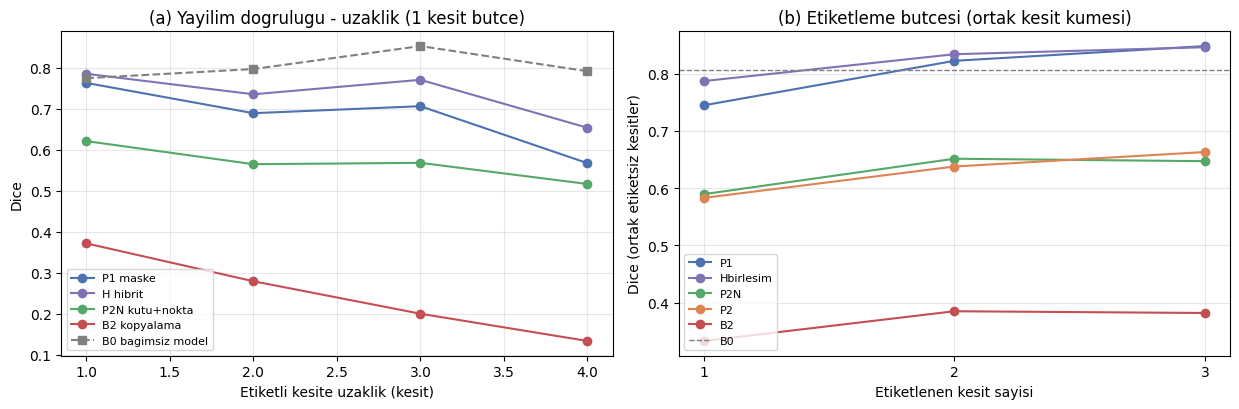

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 27.45it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 2/2 [00:00<00:00,  4.15it/s]


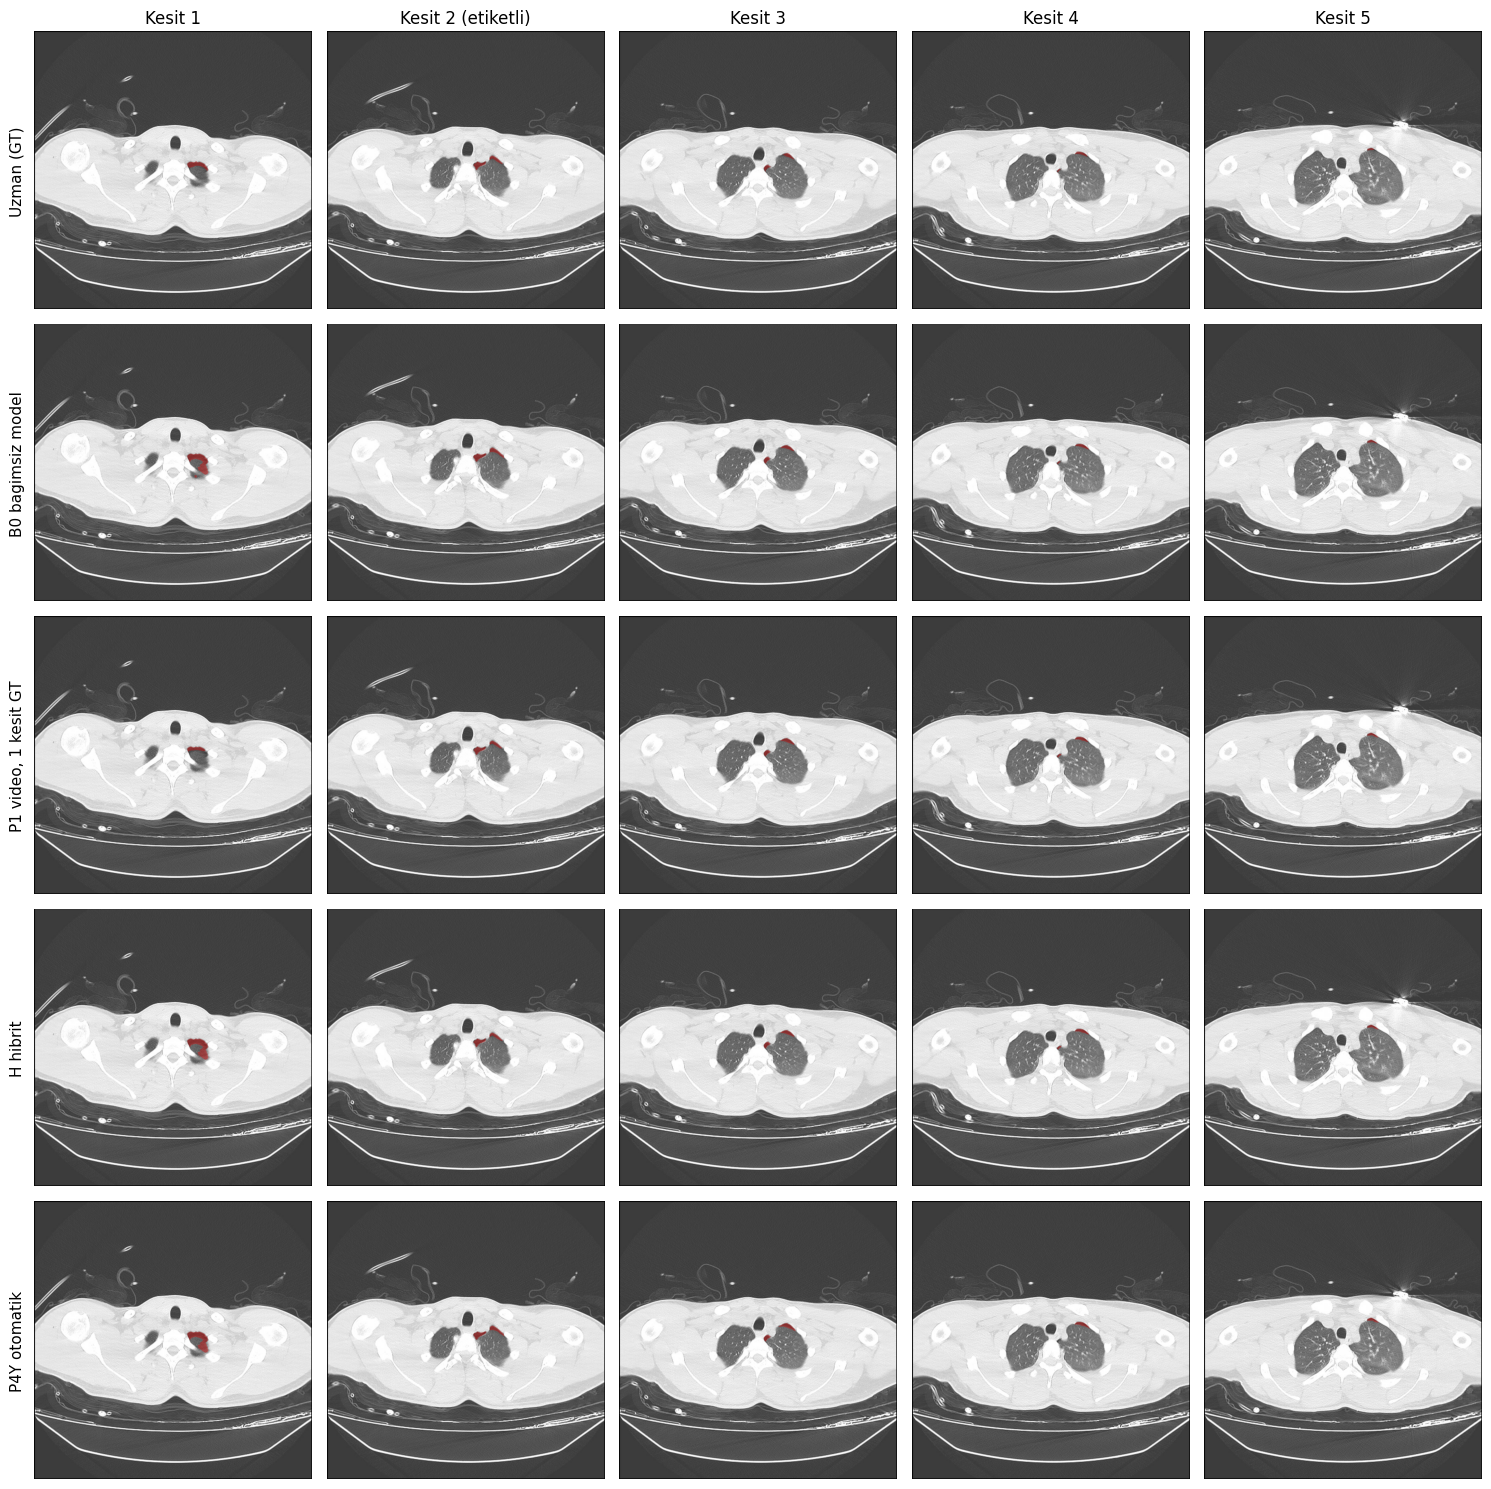

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
for y, c, et in [('P1_b1', '#4C72B0', 'P1 maske'), (HB, '#8172B3', 'H hibrit'), ('P2N_b1', '#55A868', 'P2N kutu+nokta'), ('B2_b1', '#C44E52', 'B2 kopyalama')]:
    g = res[(res.yontem == y) & ~res.etiketli_kesit].groupby('uzaklik').dice.mean()
    ax[0].plot(g.index, g.values, 'o-', label=et, color=c)
ax[0].plot(b0_uz.index, b0_uz.values, 's--', color='gray', label='B0 bagimsiz model')
ax[0].set_xlabel('Etiketli kesite uzaklik (kesit)'); ax[0].set_ylabel('Dice'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[0].set_title('(a) Yayilim dogrulugu - uzaklik (1 kesit butce)')
cc = tabloC.reset_index()
for y, c in [('P1', '#4C72B0'), (EN_IYI_HIBRIT, '#8172B3'), ('P2N', '#55A868'), ('P2', '#DD8452'), ('B2', '#C44E52')]:
    g = cc[cc.yontem == y]
    ax[1].plot(g.butce, g.Dice, 'o-', label=y, color=c)
ax[1].axhline(cc[cc.yontem == 'B0'].Dice.iloc[0], color='gray', ls='--', lw=1, label='B0')
ax[1].set_xticks([1, 2, 3]); ax[1].set_xlabel('Etiketlenen kesit sayisi'); ax[1].set_ylabel('Dice (ortak etiketsiz kesitler)')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3); ax[1].set_title('(b) Etiketleme butcesi (ortak kesit kumesi)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_uzaklik_butce.png', dpi=300); plt.show()

# Ornek hasta: kesit serisi boyunca GT / B0 / P1 / H / P4Y
ornek_pid = res[(res.yontem == 'P1_b1') & res.gt_pos].groupby('patient_id').size().idxmax()
s = hasta_calistir(ornek_pid, butceler=(1,), boyutlar=(ANA_BOYUT,), ana_boyut=ANA_BOYUT, taus=(EN_IYI_TAU,),
                   hibrit_kurallar=[SECILI_HIBRIT], yumusak_taus=(EN_IYI_TAU_Y,))
imgs, gts = VERI[ornek_pid]['imgs'], VERI[ornek_pid]['gts']
satir = [('Uzman (GT)', gts), ('B0 bagimsiz model', s['B0']), ('P1 video, 1 kesit GT', s['P1_b1']),
         ('H hibrit', s[HB]), ('P4Y otomatik', s[f'P4Y_t{EN_IYI_TAU_Y}'])]
fig, ax = plt.subplots(len(satir), len(imgs), figsize=(3 * len(imgs), 3 * len(satir)))
for r_, (t, ms) in enumerate(satir):
    for c_ in range(len(imgs)):
        ax[r_, c_].imshow(po.make_overlay(imgs[c_], ms[c_])); ax[r_, c_].axis('off')
        if r_ == 0:
            ax[r_, c_].set_title(f'Kesit {c_ + 1}' + (' (etiketli)' if c_ in s['_anahtar'].get(1, []) else ''))
    ax[r_, 0].text(-30, imgs[0].shape[0] / 2, t, rotation=90, va='center', ha='right', fontsize=11)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_ornek_hasta_seri.png', dpi=200); plt.show()